# 03 — Enrichissement du dataset

**Objectif :** ajouter à `dataset_v2.csv` de nouvelles variables explicatives **disponibles en carte mondiale**, avant la sélection rigoureuse des variables (`02_selection_variables.ipynb`, partie B). Produit `data/dataset_v3.csv`.

| Variable | Source | Pourquoi |
|---|---|---|
| `clay`, `sand` (%) | SoilGrids 2.0, 5–15 cm | texture du sol : l'argile protège la matière organique des microbes et joue donc sur la disponibilité du substrat ; citée dans la description initiale du projet |
| `SOC` (g/kg) | SoilGrids 2.0, 5–15 cm | quantité de carbone organique, c'est-à-dire de substrat pour les microbes |
| `CN` | SOC / azote, SoilGrids 2.0 | qualité du substrat (testée par Hacopian, sans effet significatif chez lui) |
| `biome` | RESOLVE Ecoregions 2017 | type de couvert végétal : effet significatif chez Hacopian (ANOVA, P = 0.004) |
| `SWC_mean` (m³/m³) | ERA5-Land 1995–2024, couche 0–7 cm | humidité du sol moyenne : l'eau conditionne l'activité microbienne |
| `SWC_warm_rel` | ERA5-Land 1995–2024, couche 0–7 cm | humidité des 3 mois les plus chauds rapportée à la moyenne annuelle : un sol sec en été bride les microbes quand il fait chaud |

Les fichiers SoilGrids et RESOLVE sont téléchargés une seule fois dans `data/externe/` (dossier ignoré par git). ERA5-Land est lu via **Google Earth Engine** (projet `crp-geosciences`) : exécuter ce notebook demande un compte Earth Engine authentifié (`earthengine authenticate`).

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat** / **Décision**.

In [1]:
# Imports : fichiers, données, graphiques, rasters (rasterio, pyproj), cartes vectorielles (geopandas), Google Earth Engine (ee)
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import pyproj
import geopandas as gpd
import ee
from rasterio.transform import rowcol

In [2]:
# Valeur fixe de Q10 à battre, définie une seule fois dans src/protocole.py
import sys
sys.path.append("..")
from src.protocole import Q10_REFERENCE

In [3]:
# Chargement de la version de référence (une ligne par site)
df = pd.read_csv("../data/dataset_v2.csv")

In [4]:
# Dossier des fichiers externes (non versionné par git)
externe = Path("../data/externe")
externe.mkdir(exist_ok=True)

## Étape 1 — Variables de sol (SoilGrids 2.0)

**Objectif :** extraire la texture (argile, sable) et le carbone organique du sol à chaque site.

**Raisonnement :**
- Profondeur **5–15 cm**, comme `N515` déjà présent dans le dataset.
- Version de SoilGrids **agrégée à 5 km**, avec la **moyenne des pixels valides sur 3×3 pixels (≈ 15 km)** autour du site. Trois raisons à ce choix : (1) à la résolution native de 250 m, 8 sites tombent sur des pixels masqués (villes, plans d'eau) ; (2) on limite l'effet de l'imprécision des coordonnées ; (3) on se rapproche de l'échelle de la carte finale (grille ORCHIDEE de 0.5°, soit ≈ 50 km).
- **Validation :** on ré-extrait l'azote avec la même méthode et on le compare à `N515`. Si les deux concordent, les nouvelles variables sont cohérentes avec celles du dataset.
- Le limon n'est pas extrait : il vaut 100 % − argile − sable, donc il n'apporte aucune information supplémentaire.

In [5]:
# Téléchargement unique des couches SoilGrids à 5 km (≈ 9 Mo chacune), si elles sont absentes
url_sg = "https://files.isric.org/soilgrids/latest/data_aggregated/5000m/{0}/{0}_5-15cm_mean_5000.tif"
for prop in ["nitrogen", "clay", "sand", "soc"]:
    if not (externe / f"{prop}_5-15cm_mean_5000.tif").exists():
        urlretrieve(url_sg.format(prop), externe / f"{prop}_5-15cm_mean_5000.tif")

In [6]:
# Fonction : moyenne des pixels valides dans un carré de 3×3 pixels (≈ 15 km) centré sur chaque site
def soilgrids(prop):
    with rasterio.open(externe / f"{prop}_5-15cm_mean_5000.tif") as src:
        x, y = pyproj.Transformer.from_crs("EPSG:4326", src.crs, always_xy=True).transform(df.lon, df.lat)
        grille = src.read(1, masked=True)
        lignes, colonnes = rowcol(src.transform, x, y)
    return np.array([np.ma.filled(grille[l-1:l+2, c-1:c+2].mean(), np.nan) for l, c in zip(lignes, colonnes)])

In [7]:
# Validation : azote extrait par notre méthode (cg/kg, unité SoilGrids), comparé à N515 du dataset
azote = soilgrids("nitrogen")
print(f"Corrélation : {np.corrcoef(azote, df.N515)[0, 1]:.3f} | rapport médian N515 / azote extrait : {np.median(df.N515 / azote):.1f}")

Corrélation : 0.979 | rapport médian N515 / azote extrait : 10.1


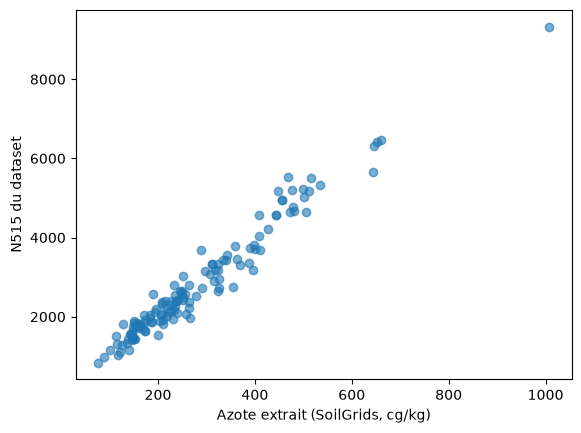

In [8]:
# Nuage de points : azote extrait contre N515
plt.scatter(azote, df.N515, alpha=0.6)
plt.xlabel("Azote extrait (SoilGrids, cg/kg)"); plt.ylabel("N515 du dataset")
plt.show()

**Constat :** corrélation de 0.98 et rapport de 10. `N515` est donc l'azote SoilGrids 5–15 cm exprimé en **mg/kg** (cg/kg × 10), et non en cg/kg comme indiqué jusqu'ici. Notre méthode reproduit presque exactement celle de l'équipe : les nouvelles variables de sol sont cohérentes avec les anciennes.

In [9]:
# Argile et sable (g/kg → %), carbone organique (dg/kg → g/kg)
df["clay"] = soilgrids("clay") / 10
df["sand"] = soilgrids("sand") / 10
df["SOC"] = soilgrids("soc") / 10

In [10]:
# Rapport C:N : carbone organique (g/kg) / azote extrait (cg/kg → g/kg), tous deux issus de la même méthode
df["CN"] = df.SOC / (azote / 100)

In [11]:
# Valeurs manquantes et plages des nouvelles variables de sol
df[["clay", "sand", "SOC", "CN"]].describe().round(1)

,clay,sand,SOC,CN
count,131.0,131.0,131.0,131.0
mean,23.3,38.2,39.4,13.4
std,7.6,14.3,30.9,4.8
min,2.7,9.8,8.5,4.2
25%,18.9,29.3,20.3,10.4
50%,24.3,35.5,32.1,12.5
75%,29.3,45.2,45.8,14.6
max,43.2,92.5,219.1,33.2


**Constat :** aucune valeur manquante. Les plages sont plausibles : argile de 3 à 43 %, sable de 10 à 93 %, carbone organique de 8 à 219 g/kg (la valeur haute correspond à un sol organique boréal), C:N de 4 à 33 (médiane 12.5, typique des sols forestiers).

## Étape 2 — Type de couvert végétal (biomes)

**Objectif :** attribuer un biome à chaque site.

**Raisonnement :** Hacopian a trouvé un effet significatif du type de couvert végétal sur Q10, à partir d'une carte mondiale des biomes. La carte de référence est **RESOLVE Ecoregions 2017** (Dinerstein et al., 2017) : 846 écorégions regroupées en 14 biomes. Chaque site prend le biome du polygone qui le contient. C'est une variable **catégorielle** : son encodage sera décidé lors de la sélection des variables.

In [12]:
# Téléchargement unique de la carte des écorégions RESOLVE 2017 (149 Mo), si elle est absente
if not (externe / "Ecoregions2017.zip").exists():
    urlretrieve("https://storage.googleapis.com/teow2016/Ecoregions2017.zip", externe / "Ecoregions2017.zip")

In [13]:
# Lecture des polygones d'écorégions, avec le nom de leur biome
eco = gpd.read_file(externe / "Ecoregions2017.zip", columns=["BIOME_NAME"])

In [14]:
# Sites sous forme de points géographiques
sites = gpd.GeoDataFrame(geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326")

In [15]:
# Biome de chaque site : celui du polygone qui contient le point
df["biome"] = gpd.sjoin(sites, eco, how="left").BIOME_NAME.values

In [16]:
# Nombre de sites par biome (et sites sans biome)
df.biome.value_counts(dropna=False)

biome
Temperate Broadleaf & Mixed Forests               71
Tropical & Subtropical Moist Broadleaf Forests    16
Temperate Conifer Forests                         14
Boreal Forests/Taiga                               9
Temperate Grasslands, Savannas & Shrublands        7
Mediterranean Forests, Woodlands & Scrub           7
Montane Grasslands & Shrublands                    5
Tropical & Subtropical Coniferous Forests          1
Deserts & Xeric Shrublands                         1
Name: count, dtype: int64

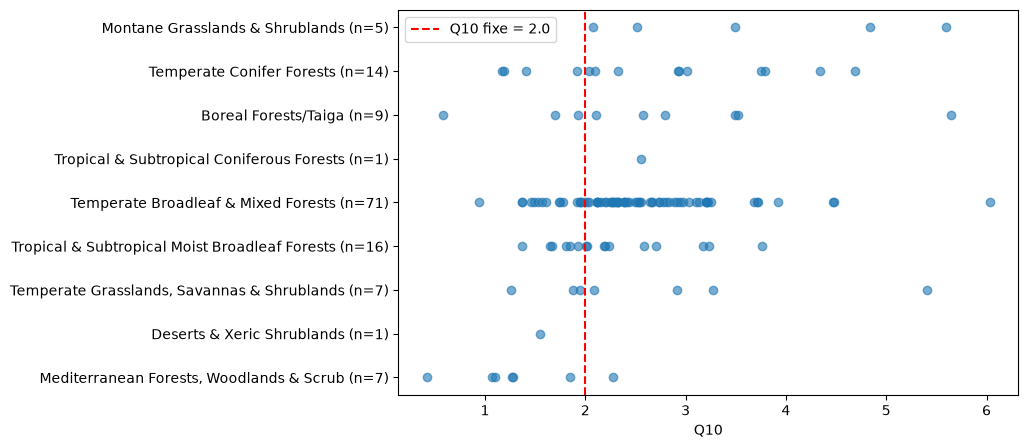

In [17]:
# Q10 de chaque site par biome (un point = un site), biomes triés par Q10 médian
ordre = df.groupby("biome").Q10.median().sort_values().index
plt.figure(figsize=(8, 5))
plt.scatter(df.Q10, df.biome.map({b: i for i, b in enumerate(ordre)}), alpha=0.6)
plt.yticks(range(len(ordre)), [f"{b} (n={(df.biome == b).sum()})" for b in ordre])
plt.axvline(Q10_REFERENCE, ls="--", c="r", label=f"Q10 fixe = {Q10_REFERENCE}")
plt.xlabel("Q10"); plt.legend()
plt.show()

**Constat :**
- Les 131 sites ont un biome (9 biomes représentés), mais très inégalement : 71 sites en forêts tempérées feuillues et mixtes, et 2 biomes avec **un seul site** (forêts tropicales de conifères, déserts). Un modèle ne peut rien apprendre de fiable d'un seul site : il faudra **regrouper** ces biomes rares avant l'encodage (décision en partie B de `02_selection_variables.ipynb`).
- Les écarts rejoignent Hacopian : Q10 le plus élevé en prairies de montagne (médiane 3.49, n = 5) et plus bas en forêts tropicales humides (2.10). Nouveauté par rapport à Hacopian : les sites méditerranéens ont le Q10 le plus bas (1.27, n = 7), ce qui est cohérent avec des étés secs qui limitent l'activité microbienne quand il fait chaud.

## Étape 3 — Humidité du sol (ERA5-Land, via Google Earth Engine)

**Objectif :** ajouter l'humidité moyenne du sol et l'humidité relative de la saison chaude.

**Raisonnement :**
- **Source ERA5-Land, période 1995–2024** : la même que MAT et MAP (Hacopian), pour que toutes les variables climatiques soient cohérentes entre elles.
- **Couche 0–7 cm** (`volumetric_soil_water_layer_1`), là où l'activité microbienne est la plus forte.
- **Climatologie mensuelle** : pour chaque mois de l'année, moyenne sur les 30 ans. La saison chaude correspond aux 3 mois les plus chauds de chaque site (température de l'air), ce qui fonctionne aussi dans l'hémisphère Sud.
- **Moyenne sur un disque de ≈ 15 km** autour du site, comme pour SoilGrids (ERA5-Land a des pixels de 0.1°, soit ≈ 11 km).
- **Validation** : on recalcule MAT et MAP avec la même méthode et on les compare aux colonnes du dataset.

In [18]:
# Connexion à Google Earth Engine (projet enregistré pour un usage non commercial)
ee.Initialize(project="crp-geosciences")

In [19]:
# ERA5-Land mensuel 1995–2024 : température de l'air, précipitations, humidité de la couche 0–7 cm
era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR").filterDate("1995-01-01", "2025-01-01").select(["temperature_2m", "total_precipitation_sum", "volumetric_soil_water_layer_1"])

In [20]:
# Climatologie : moyenne sur 30 ans de chaque mois, empilée en une seule image (3 variables × 12 mois = 36 bandes)
pile = ee.ImageCollection([era5.filter(ee.Filter.calendarRange(m, m, "month")).mean() for m in range(1, 13)]).toBands()

In [21]:
# Sites sous forme de disques de 7.5 km de rayon (≈ 15 km de diamètre, comme pour SoilGrids)
disques = ee.FeatureCollection([ee.Feature(ee.Geometry.Point(lon, lat).buffer(7500), {"i": i}) for i, (lat, lon) in enumerate(zip(df.lat, df.lon))])

In [22]:
# Extraction : moyenne de chaque bande sur chaque disque, calculée par les serveurs d'Earth Engine
res = pile.reduceRegions(disques, ee.Reducer.mean(), scale=11132).getInfo()

In [23]:
# Mise en tableau : une ligne par site (dans l'ordre du dataset), une colonne par bande
era = pd.DataFrame([f["properties"] for f in res["features"]]).sort_values("i").reset_index(drop=True)

In [24]:
# Fonction : tableau 131 sites × 12 mois pour une variable ERA5-Land
mensuel = lambda var: era[[f"{m}_{var}" for m in range(12)]].values

In [25]:
# Validation : MAT (K → °C) et MAP (m/mois → mm/an) recalculés, comparés aux colonnes du dataset
mat = (mensuel("temperature_2m") - 273.15).mean(axis=1)
map_ = mensuel("total_precipitation_sum").sum(axis=1) * 1000
print(f"MAT : r = {np.corrcoef(mat, df.MAT_public)[0, 1]:.3f} | MAP : r = {np.corrcoef(map_, df.MAP_public)[0, 1]:.3f}")

MAT : r = 0.996 | MAP : r = 0.992


**Constat :** MAT et MAP recalculés coïncident avec ceux du dataset (r > 0.99). Cela confirme que `MAT_public` et `MAP_public` viennent d'ERA5-Land 1995–2024, et que notre extraction est cohérente avec eux.

In [26]:
# Humidité moyenne annuelle de la couche 0–7 cm (m³/m³)
df["SWC_mean"] = mensuel("volumetric_soil_water_layer_1").mean(axis=1)

In [27]:
# Humidité des 3 mois les plus chauds, rapportée à la moyenne annuelle
chauds = np.argsort(mensuel("temperature_2m"), axis=1)[:, -3:]
df["SWC_warm_rel"] = np.take_along_axis(mensuel("volumetric_soil_water_layer_1"), chauds, axis=1).mean(axis=1) / df.SWC_mean

In [28]:
# Validation : comparaison avec la colonne SWC_warm_rel d'origine (retirée en v1 car sa définition était inconnue)
origine = pd.read_csv("../data/dataset.csv").drop_duplicates(["lat", "lon"])[["lat", "lon", "SWC_warm_rel"]]
comparaison = df.merge(origine, on=["lat", "lon"], suffixes=("", "_origine"))
print(f"r = {comparaison.SWC_warm_rel.corr(comparaison.SWC_warm_rel_origine):.3f}")

r = 0.983


**Constat :** r = 0.98 avec la colonne d'origine. **La définition de `SWC_warm_rel` est donc retrouvée** : humidité ERA5-Land de la couche 0–7 cm, moyenne des 3 mois les plus chauds divisée par la moyenne annuelle. La variable est maintenant claire, et on sait la recalculer partout pour la carte mondiale.

In [29]:
# Humidité relative de la saison chaude par biome (médiane)
df.groupby("biome").SWC_warm_rel.median().sort_values().round(2)

biome
Mediterranean Forests, Woodlands & Scrub          0.61
Boreal Forests/Taiga                              0.94
Temperate Grasslands, Savannas & Shrublands       0.96
Temperate Broadleaf & Mixed Forests               0.97
Deserts & Xeric Shrublands                        0.98
Temperate Conifer Forests                         0.98
Montane Grasslands & Shrublands                   1.02
Tropical & Subtropical Moist Broadleaf Forests    1.04
Tropical & Subtropical Coniferous Forests         1.11
Name: SWC_warm_rel, dtype: float64

**Constat :** les sites méditerranéens se distinguent nettement (médiane 0.61, contre 0.94 à 1.11 ailleurs) : leur sol est bien plus sec en été qu'en moyenne sur l'année. C'est cohérent avec leur Q10 bas (étape 2).

## Étape 4 — Contrôle de redondance et sauvegarde

**Objectif :** appliquer aux nouvelles variables le critère de non-redondance utilisé dans `02_selection_variables.ipynb` (seuil |r| = 0.8).

**Raisonnement :** on calcule la corrélation (Spearman) de chaque nouvelle variable numérique avec toutes les variables candidates et avec Q10.

In [30]:
# Corrélations (Spearman) des nouvelles variables avec les candidats existants et avec Q10
nouvelles = ["clay", "sand", "SOC", "CN", "SWC_mean", "SWC_warm_rel"]
df[nouvelles + ["lat", "lon", "MAT_public", "MAP_public", "pH_public", "N515", "Q10"]].corr("spearman").loc[nouvelles].round(2)

,clay,sand,SOC,CN,SWC_mean,SWC_warm_rel,lat,lon,MAT_public,MAP_public,pH_public,N515,Q10
clay,1.00,-0.76,-0.19,-0.21,0.52,0.22,-0.44,0.35,0.44,0.50,-0.03,-0.14,-0.06
sand,-0.76,1.00,0.28,0.29,-0.36,-0.05,0.23,-0.18,-0.33,-0.29,-0.23,0.22,0.09
SOC,-0.19,0.28,1.00,0.66,-0.00,-0.10,0.45,-0.08,-0.56,0.08,-0.51,0.91,0.30
CN,-0.21,0.29,0.66,1.00,-0.03,-0.15,0.38,-0.06,-0.34,-0.06,-0.34,0.38,0.02
SWC_mean,0.52,-0.36,-0.00,-0.03,1.00,0.34,-0.44,0.37,0.31,0.60,-0.25,0.03,0.01
SWC_warm_rel,0.22,-0.05,-0.10,-0.15,0.34,1.00,-0.55,0.52,0.11,0.31,0.02,-0.04,0.21


**Constat :**
- `SOC` est **redondant** avec `N515` (0.91) : le carbone et l'azote du sol varient presque ensemble.
- `clay` et `sand` sont liés (−0.76), mais restent sous le seuil.
- Les autres nouvelles variables ne sont fortement liées à aucun candidat : `CN` au plus 0.38, `SWC_mean` au plus 0.60 (avec MAP), `SWC_warm_rel` au plus 0.55 (avec `lat`).
- Liens avec Q10 : `SOC` +0.30 et `SWC_warm_rel` +0.21 ; les autres sont faibles pris isolément (rappel : ce n'est pas un motif d'exclusion).

**Décision :**
- `SOC` **n'est pas candidat** pour X. Son information est conservée par le couple `N515` + `CN`, puisque SOC = C:N × N. La colonne reste dans le dataset pour la traçabilité.
- `clay`, `sand`, `CN`, `SWC_mean`, `SWC_warm_rel` et `biome` **deviennent candidats**.

In [31]:
# Sauvegarde de la version 3 du dataset
df.to_csv("../data/dataset_v3.csv", index=False)

## Résumé

- `data/dataset_v3.csv` : 131 sites, 18 colonnes, aucune valeur manquante.
- Nouvelles variables : `clay`, `sand`, `SOC`, `CN` (SoilGrids 5–15 cm, moyenne sur ≈ 15 km), `biome` (RESOLVE 2017), `SWC_mean` et `SWC_warm_rel` (ERA5-Land 1995–2024, couche 0–7 cm, moyenne sur ≈ 15 km).
- **Candidats pour la sélection rigoureuse (12)** : `lat`, `lon`, `MAT_public`, `MAP_public`, `pH_public`, `N515`, `clay`, `sand`, `CN`, `SWC_mean`, `SWC_warm_rel`, `biome`. `SOC` est exclu car redondant avec `N515`.
- Confirmations : `N515` est en mg/kg ; `MAT_public` et `MAP_public` viennent d'ERA5-Land 1995–2024 ; la définition de `SWC_warm_rel` est retrouvée.
- À faire : regrouper les biomes rares avant l'encodage (partie B de `02_selection_variables.ipynb`).